# Training-free failure detection: raw prob vs. entropy

Two *untrained* scores for "did C0 get this right?", on the **exact rows** the
C2 pipeline evaluated:

| score | definition | shape |
|---|---|---|
| `prob`    | the C0 probability as-is                | monotone |
| `entropy` | `H(p) = -p·log p - (1-p)·log(1-p)`      | symmetric hump, peaks at p=0.5 |

No model is fit — these are the scores themselves, fed straight to `roc_curve`.
That makes them a floor for B1: B1 is a *trained* model on the single `prob`
column, so it cannot beat raw `prob` by more than fold-level calibration noise.

**Data provenance.** Rows come from the per-fold prediction CSVs of the same run
`ROC_tabular.ipynb` plots, so the folds, the patient-level split and the row
order are identical by construction — not reproduced. The `correct` column in
those CSVs is asserted below to equal `y_true` in `cv_detailed.json`.

**Orientation.** The C2 target is `correct = 1` when C0 was right. Confidence
should predict correctness *positively*, so `prob` is not the right score to
feed directly — see the sign note in the scores cell.

In [2]:
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

sys.path.insert(0, '/zhome/d0/a/221493/thesis/code')

In [3]:
# ── The run being reproduced (same directory as ROC_tabular.ipynb) ────────────
DISEASE  = 'effusion'
BASE_DIR = '/zhome/d0/a/221493/thesis'
RUN_DIR  = (f'{BASE_DIR}/results/C2_custom_corrected/{DISEASE}/cv_results_cf_ensemble'
            f'/cf_16/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)')
N_FOLDS  = 5
OUTPUT_DIR = 'images/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.isdir(RUN_DIR), f'run not found: {RUN_DIR}'
print('run:', os.path.relpath(RUN_DIR, BASE_DIR))

run: results/C2_custom_corrected/effusion/cv_results_cf_ensemble/cf_16/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)


In [4]:
# ── Load per-fold rows, and prove they are the rows the pipeline scored ───────
# cv_detailed.json holds y_true per fold; the CSV holds `correct`. If those agree
# elementwise for every fold, the CSV rows ARE the evaluated rows, in order.
detailed = json.load(open(os.path.join(RUN_DIR, 'cv_detailed.json')))

folds = []
for i in range(N_FOLDS):
    df = pd.read_csv(os.path.join(RUN_DIR, f'fold_{i}_predictions.csv'),
                     usecols=['correct', f'{DISEASE}_prob'])
    y = df['correct'].astype(int).values
    p = df[f'{DISEASE}_prob'].astype(float).values

    ref = np.asarray(detailed['MLP']['B1'][i]['y_true'], dtype=int)
    assert len(y) == len(ref) and (y == ref).all(), f'fold {i}: rows differ from cv_detailed'

    folds.append({'y': y, 'p': p})
    print(f'fold {i}: n={len(y):>6,}  correct={y.mean():.3f}')

n_tot = sum(len(f['y']) for f in folds)
print(f'\ntotal {n_tot:,} rows — `correct` == cv_detailed y_true in all {N_FOLDS} folds')

fold 0: n= 8,816  correct=0.915
fold 1: n= 8,630  correct=0.916
fold 2: n= 9,087  correct=0.919
fold 3: n= 9,194  correct=0.920
fold 4: n= 9,428  correct=0.916

total 45,155 rows — `correct` == cv_detailed y_true in all 5 folds


In [11]:
# ── The two training-free scores ─────────────────────────────────────────────
def binary_entropy(p):
    """Same clip + formula as the pipeline's _binary_entropy."""
    p = np.clip(p, 1e-10, 1 - 1e-10)
    return -p * np.log(p) - (1 - p) * np.log(1 - p)


# Sign: the positive class is `correct = 1`, and CONFIDENCE (not probability)
# predicts correctness. A raw prob near 1 means confident-positive, near 0 means
# confident-negative -- both are likely correct, so `prob` itself is non-monotone
# in the target and would score near 0.5. |p - tau| is the confidence margin.
# Entropy is high when UNSURE, so it is negated to point the same way.
TAU = float(open(f'{BASE_DIR}/results/C0_custom/{DISEASE}/threshold.txt').read().strip())
print(f'tau = {TAU:.4f}')

SCORES = {
    'Raw prob (p)':            lambda p: p,
    'Confidence |p - 0.5634 (Youden-Optimal)|':    lambda p: np.abs(p - TAU),
    'Confidence |p - 0.5|':            lambda p: np.abs(p - 0.5),
    'Negative entropy -H(p)':  lambda p: -binary_entropy(p),
    'MSP (Maximum Softmax Probability)': lambda p: np.maximum(p, 1 - p),
}

tau = 0.5634


In [13]:
# ── Per-fold AUC for each score ──────────────────────────────────────────────
rows = []
for name, fn in SCORES.items():
    aucs = [roc_auc_score(f['y'], fn(f['p'])) for f in folds]
    rows.append({'score': name, 'mean_auc': np.mean(aucs), 'std_auc': np.std(aucs, ddof=1),
                 'fold_aucs': np.round(aucs, 4)})

auc_tbl = pd.DataFrame(rows).set_index('score')
display(auc_tbl.style.format({'mean_auc': '{:.4f}', 'std_auc': '{:.4f}'}))

,mean_auc,std_auc,fold_aucs
score,,,
Raw prob (p),0.7362,0.0077,[0.7354 0.728 0.739 0.7478 0.7308]
Confidence |p - 0.5634 (Youden-Optimal)|,0.7301,0.0083,[0.7184 0.7248 0.7323 0.737 0.7378]
Confidence |p - 0.5|,0.8360,0.0067,[0.838 0.8285 0.8407 0.8434 0.8294]
Negative entropy -H(p),0.8360,0.0067,[0.838 0.8285 0.8407 0.8434 0.8294]
MSP (Maximum Softmax Probability),0.8360,0.0067,[0.838 0.8285 0.8407 0.8434 0.8294]


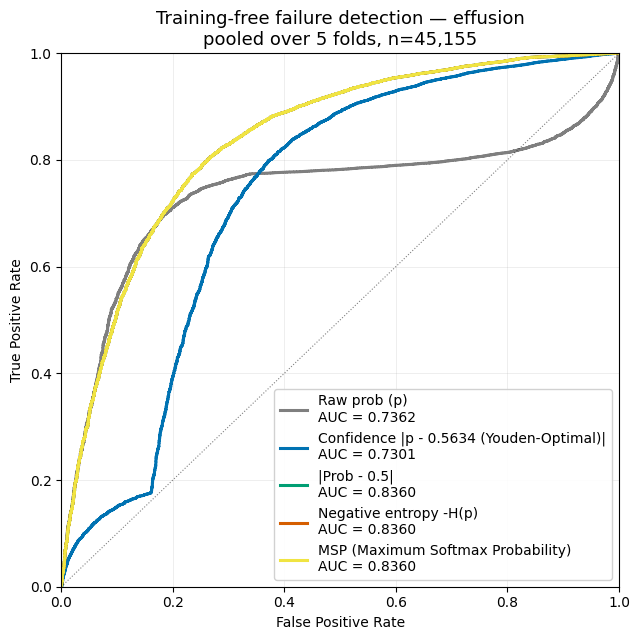

In [ ]:
# ── Pooled ROC curves ────────────────────────────────────────────────────────
# Pooled across folds (concatenate, then one ROC) so the curve is a single well
# defined object; the table above carries the fold-to-fold spread.
y_all = np.concatenate([f['y'] for f in folds])
p_all = np.concatenate([f['p'] for f in folds])

COLORS = {'Raw prob (p)': '#7F7F7F',
          'Confidence |p - 0.5634 (Youden-Optimal)|': '#0072B2',
          'Confidence |p - 0.5|': '#009E73',
          'MSP (Maximum Softmax Probability)': '#F0E442',
          'Negative entropy -H(p)': '#D55E00'}

fig, ax = plt.subplots(figsize=(6.5, 6.5))
for name, fn in SCORES.items():
    s = fn(p_all)
    fpr, tpr, _ = roc_curve(y_all, s)
    ax.plot(fpr, tpr, color=COLORS[name], lw=2.2,
            label=f'{name}\nAUC = {roc_auc_score(y_all, s):.4f}')

ax.plot([0, 1], [0, 1], 'k:', lw=0.8, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title(f'Training-free failure detection — {DISEASE}\n'
             f'pooled over {N_FOLDS} folds, n={len(y_all):,}', size=13)
ax.legend(loc='lower right', fontsize=10, framealpha=0.9)
ax.grid(alpha=0.3, lw=0.5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'roc_training_free_{DISEASE}.png'),
            dpi=300, bbox_inches='tight')
plt.show()

## Why raw `prob` and entropy are not two views of the same thing

`|p - tau|` and `-H(p)` are both "distance from the boundary" and should land close
together. Raw `p` is the odd one out: it is monotone, so it can only say
"high p ⇒ correct", while errors actually concentrate near the boundary from
*both* sides. The plot below shows the error rate against `p`, which is the
shape each score is trying to capture.

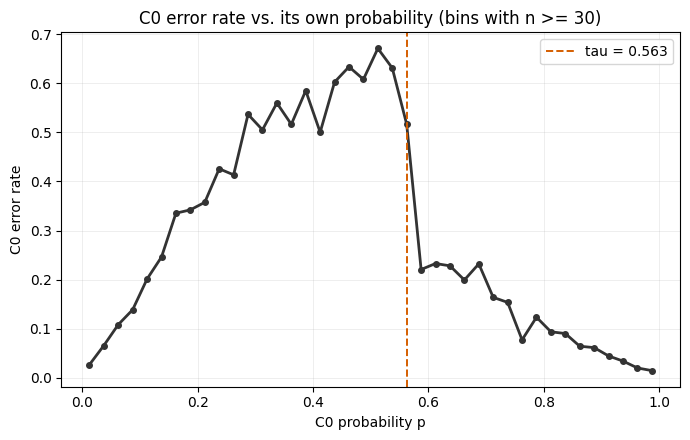

In [7]:
# ── The shape the scores are chasing: error rate vs p ────────────────────────
bins = np.linspace(0, 1, 41)
idx  = np.digitize(p_all, bins) - 1
err_rate, centres, counts = [], [], []
for b in range(len(bins) - 1):
    m = idx == b
    if m.sum() < 30:
        continue
    err_rate.append(1 - y_all[m].mean())
    centres.append((bins[b] + bins[b + 1]) / 2)
    counts.append(int(m.sum()))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(centres, err_rate, color='#333333', lw=2, marker='o', ms=4)
ax.axvline(TAU, color='#D55E00', ls='--', lw=1.4, label=f'tau = {TAU:.3f}')
ax.set_xlabel('C0 probability p'); ax.set_ylabel('C0 error rate')
ax.set_title('C0 error rate vs. its own probability (bins with n >= 30)', size=12)
ax.legend(fontsize=10); ax.grid(alpha=0.3, lw=0.5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'error_rate_vs_prob_{DISEASE}.png'),
            dpi=300, bbox_inches='tight')
plt.show()

In [14]:
# ── Compare against the TRAINED B1 from the same run ─────────────────────────
# B1 = a model fit on the single `prob` column. Training on one feature cannot
# add ranking information beyond a monotone reshaping, so B1 should not exceed
# the best training-free score by more than noise. A large gap would mean the
# fold-level calibration -- not the feature -- is doing the work.
summ = pd.read_csv(os.path.join(RUN_DIR, 'cv_summary.csv'))
b1 = summ[summ['config'] == 'B1'][['model', 'config', 'mean_auc', 'std_auc']]

best_free = auc_tbl['mean_auc'].max()
print(f'best training-free score : {best_free:.4f}  ({auc_tbl["mean_auc"].idxmax()})')
print()
print('trained B1 from the same run:')
display(b1.style.format({'mean_auc': '{:.4f}', 'std_auc': '{:.4f}'}, subset=['mean_auc', 'std_auc']))
print(f'gap (best B1 - best training-free): {b1["mean_auc"].max() - best_free:+.4f}')

best training-free score : 0.8360  (Confidence |p - 0.5|)

trained B1 from the same run:


,model,config,mean_auc,std_auc
0,LR,B1,0.7362,0.0069
16,RF,B1,0.7502,0.0091
32,MLP,B1,0.8501,0.0086


gap (best B1 - best training-free): +0.0141


In [14]:
TAU

0.5634

In [24]:
# ── TRAINED B1 variants: prob-only vs entropy-only vs confidence-only ────────
# Same recipe as c2_cv_pipeline_cf_ensemble.py's B1 (a one-column design matrix),
# same models, same splits: StratifiedGroupKFold(5, shuffle, seed=42) on
# patient_id over c2_data.csv. B1 uses no counterfactuals, so the CF retrieval
# step is irrelevant here and the fold split alone reproduces the pipeline.
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

RESULTS_DIR = '/work3/s251710/thesis_results'
RANDOM_SEED = 42

data = pd.read_csv(f'{RESULTS_DIR}/C2_custom/{DISEASE}/c2_data.csv')
# 'prob' is the C0 probability (not the prediction) -- renamed as the pipeline does.
data = data.rename(columns={'prob': f'{DISEASE}_prob'})
p_col = data[f'{DISEASE}_prob'].astype(float).values
y_col = data['correct'].astype(int).values
print(f'{len(data):,} rows | correct={y_col.mean():.3f}')

# The three single-column feature variants.
FEATURES = {
    'prob':       p_col,
    'entropy':    binary_entropy(p_col),
    'confidence': np.abs(p_col - 0.5),
    'confidence (y)': np.abs(p_col - TAU)
}


def fit_predict(X_tr, X_te, y_tr, model_type):
    """Mirrors train_model() in the pipeline, minus the CF-rank expansion."""
    if model_type == 'LR':
        sc = StandardScaler()
        m = LogisticRegression(max_iter=5000, class_weight='balanced',
                               random_state=RANDOM_SEED)
        m.fit(sc.fit_transform(X_tr), y_tr)
        return m.predict_proba(sc.transform(X_te))[:, 1]
    if model_type == 'RF':
        m = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                   random_state=RANDOM_SEED, n_jobs=-1)
        m.fit(X_tr, y_tr)
        return m.predict_proba(X_te)[:, 1]
    if model_type == 'MLP':
        sc = StandardScaler()
        m = MLPClassifier(hidden_layer_sizes=(64, 32, 16), max_iter=500,
                          early_stopping=True, validation_fraction=0.05,
                          random_state=RANDOM_SEED)
        m.fit(sc.fit_transform(X_tr.astype(np.float32)), y_tr)
        return m.predict_proba(sc.transform(X_te.astype(np.float32)))[:, 1]
    raise ValueError(model_type)


skf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
splits = list(skf.split(data, y_col, groups=data['patient_id'].values))

rows_b1 = []
for feat_name, feat in FEATURES.items():
    print(f'\nB1 variant: {feat_name}')
    X = feat.reshape(-1, 1)
    for model_type in ['LR', 'RF', 'MLP']:
        aucs = []
        for tr, te in splits:
            s = fit_predict(X[tr], X[te], y_col[tr], model_type)
            aucs.append(roc_auc_score(y_col[te], s))
        rows_b1.append({'feature': feat_name, 'model': model_type,
                        'mean_auc': np.mean(aucs), 'std_auc': np.std(aucs, ddof=1),
                        'fold_aucs': np.round(aucs, 4)})
        print(f'{feat_name:>10} | {model_type:<3} | AUC = {np.mean(aucs):.4f} '
              f'± {np.std(aucs, ddof=1):.4f}')

b1_variants = pd.DataFrame(rows_b1)
display(b1_variants.set_index(['feature', 'model'])
        .style.format({'mean_auc': '{:.4f}', 'std_auc': '{:.4f}'}))

45,155 rows | correct=0.917

B1 variant: prob
      prob | LR  | AUC = 0.7362 ± 0.0077
      prob | RF  | AUC = 0.7502 ± 0.0101
      prob | MLP | AUC = 0.8501 ± 0.0096

B1 variant: entropy
   entropy | LR  | AUC = 0.8360 ± 0.0067
   entropy | RF  | AUC = 0.7182 ± 0.0084
   entropy | MLP | AUC = 0.8360 ± 0.0067

B1 variant: confidence
confidence | LR  | AUC = 0.8360 ± 0.0067
confidence | RF  | AUC = 0.7179 ± 0.0083
confidence | MLP | AUC = 0.8360 ± 0.0067

B1 variant: confidence (y)
confidence (y) | LR  | AUC = 0.7301 ± 0.0083
confidence (y) | RF  | AUC = 0.6736 ± 0.0158
confidence (y) | MLP | AUC = 0.7415 ± 0.0303


In [25]:
b1_variants

,feature,model,mean_auc,std_auc,fold_aucs
0,prob,LR,0.736181,0.007726,"[0.7354, 0.728, 0.739, 0.7478, 0.7308]"
1,prob,RF,0.750232,0.010138,"[0.7594, 0.7411, 0.7605, 0.7517, 0.7385]"
2,prob,MLP,0.850072,0.009630,"[0.8561, 0.8422, 0.856, 0.8587, 0.8373]"
3,entropy,LR,0.835986,0.006711,"[0.838, 0.8285, 0.8407, 0.8434, 0.8294]"
4,entropy,RF,0.718221,0.008381,"[0.7076, 0.7173, 0.7278, 0.7252, 0.7131]"
5,entropy,MLP,0.835986,0.006711,"[0.838, 0.8285, 0.8407, 0.8434, 0.8294]"
6,confidence,LR,0.835986,0.006711,"[0.838, 0.8285, 0.8407, 0.8434, 0.8294]"
7,confidence,RF,0.717890,0.008343,"[0.7073, 0.7171, 0.7272, 0.7252, 0.7126]"
8,confidence,MLP,0.835986,0.006711,"[0.838, 0.8285, 0.8407, 0.8434, 0.8294]"
9,confidence (y),LR,0.730073,0.008313,"[0.7184, 0.7248, 0.7323, 0.737, 0.7378]"


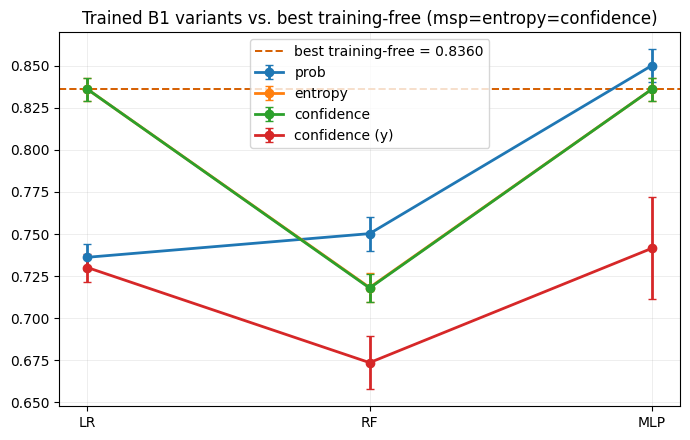

In [26]:
# Plot the 3 B1 variants across 3 model types, 
plt.figure(figsize=(7, 4.5))
for feat_name in FEATURES.keys():
    df = b1_variants[b1_variants['feature'] == feat_name]
    plt.errorbar(df['model'], df['mean_auc'], yerr=df['std_auc'], label=feat_name,
                 marker='o', capsize=3, lw=2)
plt.axhline(best_free, color='#D55E00', ls='--', lw=1.4, label=f'best training-free = {best_free:.4f}')
plt.title(f'Trained B1 variants vs. best training-free (msp=entropy=confidence)')
plt.legend(fontsize=10); plt.grid(alpha=0.3, lw=0.5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'roc_b1_variants_{DISEASE}.png'), dpi=300, bbox_inches='tight')
plt.show()

In [18]:
print(TAU)



0.5634


In [19]:
print(TAU)

insp = pd.DataFrame({
    'prob':       FEATURES['prob'],
    'entropy':    FEATURES['entropy'],
    'confidence': FEATURES['confidence'],
})
print(insp.head(10))
print(np.corrcoef(insp['entropy'], insp['confidence'])[0, 1])


0.5634
       prob   entropy  confidence
0  0.041813  0.173663    0.521587
1  0.215630  0.521321    0.347770
2  0.989880  0.056552    0.426480
3  0.803541  0.495454    0.240141
4  0.022438  0.107380    0.540962
5  0.202297  0.503571    0.361103
6  0.061508  0.231097    0.501892
7  0.029149  0.131771    0.534251
8  0.014168  0.074379    0.549232
9  0.019921  0.097732    0.543479
-0.8223394099236923


In [21]:
# error rate as a function of p, in bins. Where does it actually peak?
insp = pd.DataFrame({'prob': p_col, 'correct': y_col})
bins = np.linspace(0, 1, 21)
insp['bin'] = pd.cut(insp['prob'], bins)
print(insp.groupby('bin', observed=True)['correct'].agg(['mean', 'size']))


                 mean   size
bin                         
(0.0, 0.05]  0.956563   5226
(0.05, 0.1]  0.879542   2009
(0.1, 0.15]  0.779886   1054
(0.15, 0.2]  0.661585    656
(0.2, 0.25]  0.610790    519
(0.25, 0.3]  0.529976    417
(0.3, 0.35]  0.468354    395
(0.35, 0.4]  0.449864    369
(0.4, 0.45]  0.447514    362
(0.45, 0.5]  0.379501    361
(0.5, 0.55]  0.350829    362
(0.55, 0.6]  0.639175    388
(0.6, 0.65]  0.769565    460
(0.65, 0.7]  0.783394    554
(0.7, 0.75]  0.841629    663
(0.75, 0.8]  0.896835    853
(0.8, 0.85]  0.908205   1231
(0.85, 0.9]  0.937143   2100
(0.9, 0.95]  0.962054   4480
(0.95, 1.0]  0.983830  22696


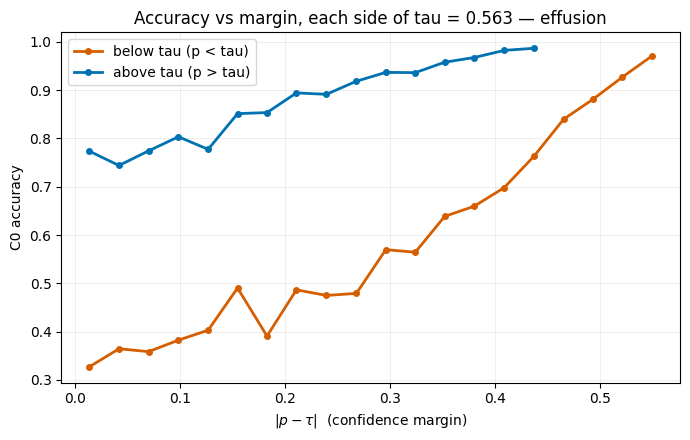

mean                      \
side                above tau (p > tau) below tau (p < tau)   
centre                                                        
0.0141                         0.773585            0.327189   
0.04225                        0.744000            0.364532   
0.0704                         0.774319            0.358586   
0.09875                        0.803390            0.382353   
0.127                          0.777439            0.402913   
0.155                          0.851351            0.490291   
0.183                          0.853535            0.390863   
0.21100000000000002            0.894309            0.486607   
0.2395                         0.891341            0.474886   
0.268                          0.918455            0.479263   
0.296                          0.936782            0.569721   
0.324                          0.936236            0.564394   
0.352                          0.957868            0.638629   
0.38                           0.967505            0.659639   
0.4085                         0.982306            0.697987   
0.437                          0.986720            0.763441   
0.46499999999999997                 NaN            0.839646   
0.493                               NaN            0.881072   
0.521                               NaN            0.927064   
0.5489999999999999                  NaN            0.970623   

                                   size                      
side                above tau (p > tau) below tau (p < tau)  
centre                                                       
0.0141                            212.0               217.0  
0.04225                           250.0               203.0  
0.0704                            257.0               198.0  
0.09875                           295.0               204.0  
0.127                             328.0               206.0  
0.155                             370.0               206.0  
0.183                             396.0               197.0  
0.21100000000000002               492.0               224.0  
0.2395                            589.0               219.0  
0.268                             699.0               217.0  
0.296                            1044.0               251.0  
0.324                            1286.0               264.0  
0.352                            1970.0               321.0  
0.38                             3816.0               332.0  
0.4085                           9721.0               447.0  
0.437                           11596.0               558.0  
0.46499999999999997                 NaN               792.0  
0.493                               NaN              1194.0  
0.521                               NaN              2180.0  
0.5489999999999999                  NaN              3404.0

In [25]:
# ── Accuracy vs signed distance from tau: the two arms are not symmetric ─────
d = p_col - TAU
insp = pd.DataFrame({'d': d, 'correct': y_col})

# Bin each arm on |d| so the two curves are directly comparable point-for-point.
edges = np.linspace(0, max(TAU, 1 - TAU), 21)
insp['side'] = np.where(insp['d'] < 0, 'below tau (p < tau)', 'above tau (p > tau)')
insp['absbin'] = pd.cut(insp['d'].abs(), edges)

g = (insp.groupby(['side', 'absbin'], observed=True)['correct']
        .agg(['mean', 'size']).reset_index())
g['centre'] = g['absbin'].apply(lambda i: (i.left + i.right) / 2)
g = g[g['size'] >= 30]          # same cutoff as the existing error-rate plot

fig, ax = plt.subplots(figsize=(7, 4.5))
for side, colour in [('below tau (p < tau)', '#D55E00'),
                     ('above tau (p > tau)', '#0072B2')]:
    s = g[g['side'] == side]
    ax.plot(s['centre'], s['mean'], color=colour, lw=2, marker='o', ms=4, label=side)

ax.set_xlabel(r'$|p - \tau|$  (confidence margin)')
ax.set_ylabel('C0 accuracy')
ax.set_title(f'Accuracy vs margin, each side of tau = {TAU:.3f} — {DISEASE}', size=12)
ax.legend(fontsize=10); ax.grid(alpha=0.3, lw=0.5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'accuracy_vs_margin_by_side_{DISEASE}.png'),
            dpi=300, bbox_inches='tight')
plt.show()

display(g.pivot(index='centre', columns='side', values=['mean', 'size']))
